In [1]:
# Colab only: clone (or update) the repo on the joe branch and move into the project root
import os
import sys

if 'google.colab' in sys.modules:
    REPO = '/content/convolutional_vae_quishing'
    BRANCH = 'joe'
    if not os.path.exists(REPO):
        !git clone -b {BRANCH} https://github.com/AnhJoe/convolutional_vae_quishing.git {REPO}
    else:
        !git -C {REPO} fetch origin
        !git -C {REPO} checkout {BRANCH}
        !git -C {REPO} pull origin {BRANCH}
    os.chdir(REPO)

remote: Enumerating objects: 23, done.
remote: Counting objects: 100% (23/23), done.
remote: Compressing objects: 100% (5/5), done.
remote: Total 12 (delta 7), reused 12 (delta 7), pack-reused 0 (from 0)
Unpacking objects: 100% (12/12), 290.52 KiB | 11.17 MiB/s, done.
From https://github.com/AnhJoe/convolutional_vae_quishing
   666b6ce..c9d1b85  joe        -> origin/joe
Already on 'joe'
Your branch is behind 'origin/joe' by 1 commit, and can be fast-forwarded.
  (use "git pull" to update your local branch)
From https://github.com/AnhJoe/convolutional_vae_quishing
 * branch            joe        -> FETCH_HEAD
Updating 666b6ce..c9d1b85
Fast-forward
 .../275p_Project_Proposal_URL_VAE_revised.docx     |  Bin 682422 -> 0 bytes
 README.md                                          |   54 +-
 notebooks/4_url_vae.ipynb                          |  732 ++++-------
 notebooks/5_supervised_reference.ipynb             |  277 +---
 notebooks/6_results.ipynb                          | 1379 ++++++++++++

In [2]:
#| output: false
# Find the project root (the folder containing src/) and add it to the import path. Run this on Colab too.

import sys
from pathlib import Path

# Set to root for src load
root = Path.cwd()
while root != root.parent and not (root / "src").exists():
    root = root.parent

if not (root / "src").exists():
    raise FileNotFoundError("Could not find 'src' folder above current working directory.")

sys.path.insert(0, str(root))
print("Project root:", root)

Project root: /content/convolutional_vae_quishing


# Results

This notebook is the final evaluation. It trains nothing: it reads the scores saved under `results/` and answers the questions of the report. Run `3_floors.ipynb`, `4_url_vae.ipynb` and `5_supervised_reference.ipynb` first (three seeds each for the URL VAE and the supervised reference). The analysis code lives in `src/analysis.py`. The bootstrap cells take a minute or two each; set `N_BOOT = 200` for a quick look.

**How the uncertainty is measured.** URLs from the same site are not independent, so the 95% confidence intervals resample whole **domains** of the test set with replacement (1,000 times) and recompute each metric every time. The interval is the middle 95% of those results. When two scores are compared, the same resampled data is used for both (a paired comparison), so the interval says whether one score beats the other on the same data. The alarm thresholds stay fixed at their validation values. A model with several seeds is summarized by its mean over seeds, computed inside every resample, so the interval describes the test data. The spread across seeds is reported next to it and is not part of the interval.

**What was fixed before looking at the test set.** The headline VAE score is the one with the higher average validation AUROC. The success criteria are the ones in the proposal: the VAE beats floor A, it does so in most strata, and the share of the floor-to-reference gap it closes is reported without a threshold. Not meeting a criterion is a finding, not a failure.

In [3]:
# Imports and settings
import json

import numpy as np
import pandas as pd

from src import checks
from src.analysis import FLOOR_A, FLOOR_B, Analysis, list_runs
from src.inspect_vae import (active_units, example_nll, latent_sample, pca_2d, prior_samples, surprise_examples)
from src.nn_common import encode_items, get_device
from src.plots import plot_detection, plot_latent, plot_score_distributions, plot_strata, plot_surprise
from src.prepare_data import load_items
from src.url_vae import load_vae
from src.splits import SPLIT_NAMES

PROC_DIR = root / "data" / "processed"
RESULTS_DIR = root / "results"
ARTIFACTS_DIR = root / "data" / "artifacts"     # model weights and training histories (git-ignored)
N_BOOT = 1000       # bootstrap replicates (use 200 for a quick look)

## 1. Data

`load_items` reads the items table built by `2_data_processing.ipynb` (one row per kept URL, with its label, split and URL features). The data checks below confirm that the table is the one everyone on the team should have.

In [4]:
# Load the items table and its summary, then count the URLs per split and class
items = load_items(PROC_DIR)
summary = json.loads((PROC_DIR / "items_summary.json").read_text())
items.groupby(["split", "cls"]).size().unstack().loc[SPLIT_NAMES]

cls,benign,malicious
split,,
train,300969,403020
validation,64494,86361
test,64494,86362


**Checks on the data.** The next cell runs a set of checks on the items table and prints one row per check. Each row is `pass` or `FAIL`, and the cell stops with an error if any check fails, so a broken table cannot reach a model by accident. The checks confirm that the table matches `items_summary.json` (the row counts and the data version, which everyone on the team should see as the same value), that every split has both classes, that no registered domain sits in two splits of the same class, and that the URL columns are consistent.

In [5]:
# Run the data checks on the items table (stops with an error if any check fails)
checks.data_checks(items, summary).report()

check,result,detail
row count matches items_summary.json,pass,"1,005,700 rows"
data version matches items_summary.json,pass,08d6fa626da8. Everyone on the team should see the same value
item_id equals the row position,pass,
label matches the class folder,pass,
rows per split and class match items_summary.json,pass,"train: 300,969 benign, 403,020 malicious; validation: 64,494 benign, 86,361 malicious; test: 64,494 benign, 86,362 malicious"
every split has benign and malicious rows,pass,
no domain appears in two splits of the same class,pass,
malicious share of every split is within 1 point of the overall share,pass,"train 0.572, validation 0.572, test 0.572 (overall 0.572)"
"no empty URL, and url_len equals the URL length",pass,
truncated is true exactly for URLs longer than 256,pass,"5,742 truncated"


**Checks on the analysis.** The next cell tests the analysis code on made-up scores in a temporary folder: the weighted metrics must equal the plain metrics, a random score must have an interval around 0.5, an informative score must beat a random one and a reversed score must lose to it, a score compared with itself must give a difference of exactly 0, and a stratum must get an AUROC only when it has enough items and enough domains of both classes. It takes about half a minute.

In [6]:
# Run the analysis checks on made-up scores
checks.analysis_checks(items).report()

check,result,detail
weighted AUROC and AUPRC equal src/evaluate.py with equal weights,pass,
integer weights equal repeating the rows (AUROC and AUPRC),pass,
the weighted AUROC equals the AUROC in the metrics table,pass,
bootstrap replicates of a random scorer are centred near 0.5,pass,"mean 0.499, sd 0.0016"
the 95% interval of a random scorer's AUROC contains 0.5,pass,"[0.497, 0.502]"
"an informative score beats a random one (paired interval above 0), overall and for every seed",pass,difference +0.182
a reversed score is below a random one (interval below 0),pass,
"a score compared with itself has difference 0 and interval [0, 0]",pass,
a stratum has an AUROC exactly when both classes have enough items and domains,pass,7 of 9 strata eligible (at least 100 items and 10 domains per class)
a stratum with 150 rows per class from one domain is not eligible,pass,1 domain per class


## 2. Runs found

Every model, score and seed that has saved scores under `results/`. The URL VAE and the supervised reference should each show three seeds (0, 1, and 2). If one shows fewer, finish `4_url_vae.ipynb` or `5_supervised_reference.ipynb` first.

In [7]:
# Create the analysis object and list the runs it found: seeds per model and score, and the validation AUROC that picks the headline score
an = Analysis(RESULTS_DIR, items, n_boot=N_BOOT)
an.seed_summary()[["model", "score", "n_seeds", "validation_auroc"]].round(3)

,model,score,n_seeds,validation_auroc
0,floorA_url,abs_z,1,0.588
1,floorB_url,mahalanobis,1,0.766
2,url_supervised,prob_malicious,3,0.975
3,url_vae,neg_elbo_per_char,3,0.816
4,url_vae,nll_per_char,3,0.812


## 3. Headline score

The VAE has two scores. The one with the higher **validation** AUROC is the headline score, so the choice never uses the test set.

In [8]:
# Choose the VAE's headline score on validation AUROC
SCORE = an.choose_score("url_vae")
SCORE

'neg_elbo_per_char'

## 4. Test metrics with confidence intervals

AUROC, AUPRC and recall at 1% and 5% false-positive rate (FPR), each as value [low, high] with its 95% interval. A random scorer has an AUROC of 0.5 and an AUPRC equal to the malicious share (about 0.57).

In [9]:
# Test metrics with domain-bootstrap intervals for the floors, the VAE and the reference
an.metrics_table()

,model,score,n_seeds,AUROC,AUPRC,recall at 1% FPR,recall at 5% FPR
0,floorA_url,abs_z,1,"0.587 [0.584, 0.590]","0.631 [0.627, 0.635]","0.014 [0.013, 0.015]","0.031 [0.030, 0.032]"
1,floorB_url,mahalanobis,1,"0.764 [0.761, 0.767]","0.804 [0.801, 0.807]","0.096 [0.094, 0.098]","0.282 [0.279, 0.285]"
2,url_supervised,prob_malicious,3,"0.975 [0.974, 0.975]","0.979 [0.978, 0.980]","0.584 [0.581, 0.586]","0.904 [0.902, 0.905]"
3,url_vae,neg_elbo_per_char,3,"0.817 [0.815, 0.820]","0.864 [0.862, 0.867]","0.210 [0.207, 0.212]","0.456 [0.453, 0.459]"
4,url_vae,nll_per_char,3,"0.814 [0.812, 0.816]","0.862 [0.860, 0.865]","0.209 [0.207, 0.212]","0.454 [0.451, 0.457]"


## 5. Does the VAE beat its floor?

The difference in test AUROC (average over seeds) between the VAE and each floor, with its 95% interval. An interval entirely above 0 means the VAE beats that floor on the same resampled data. Floor A is the headline floor and floor B is the stricter one, reported alongside. The seeds one at a time are the dots in figure 8.1 and the seed robustness row of section 7.

In [10]:
# Paired AUROC difference (mean over seeds): VAE minus floor A (the headline floor) and minus floor B (the stricter floor, reported alongside)
an.floor_comparison("url_vae", SCORE).round(3)

,floor,model_auroc,floor_auroc,difference,ci_low,ci_high,beats_floor
0,floor A,0.817,0.587,0.231,0.227,0.234,True
1,floor B,0.817,0.764,0.053,0.050,0.057,True


## 6. Does it hold within strata?

The strata figure splits the test URLs by URL length and by scheme, so a model that only wins on, say, URLs without a scheme is caught. A stratum gets an AUROC only if it has at least 100 benign and 100 malicious test URLs from at least 10 registered domains of each class (our rule for a stable AUROC, where the domain count guards against a few domains supplying all the rows). Smaller strata have no AUROC and are named under the figure. The labels give the number of benign and malicious test URLs of each stratum, and the numbers on the right are the paired difference to floor A with its 95% interval. The IP-host group is reported as counts and shares only, because almost no benign URL has an IP host.

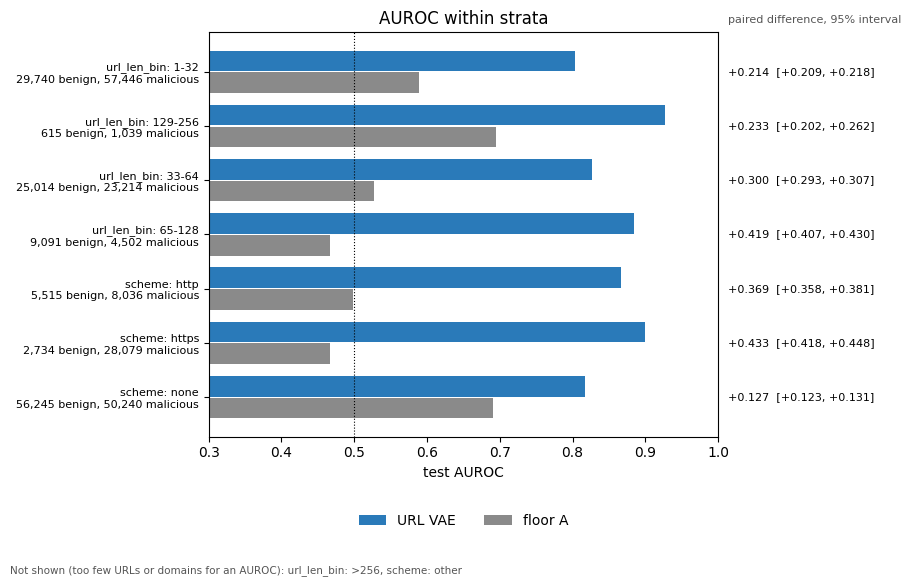

In [11]:
# AUROC of the VAE and of floor A inside each stratum, with the paired difference and its interval
strata = an.strata("url_vae", SCORE, *FLOOR_A)
plot_strata(strata);

In [12]:
# URLs with an IP-address host in the test split, per class (counts only, no AUROC)
an.ip_host_table()

,cls,ip_host_items,items,share_of_class
0,benign,12,64494,0.000186
1,malicious,1995,86362,0.023100


**URLs cut off at 256 characters.** The model reads at most 256 characters. The next table shows the share of URLs that were cut, per split and class. Report the malicious test share with the results.

In [13]:
# Share of URLs cut off at 256 characters, per split and class
items.groupby(["split", "cls"])["truncated"].mean().unstack().loc[SPLIT_NAMES].round(4)

cls,benign,malicious
split,,
train,0.0004,0.0130
validation,0.0004,0.0017
test,0.0005,0.0019


## 7. Success criteria

The criteria of the proposal for the VAE's headline score, each with its numbers (beats floor A, and holds within strata). The last rows are information, not pass or fail: the comparison with floor B and the share of the gap between floor A and the supervised reference that the VAE closes (0 means no better than the floor, 1 means as good as the reference). Remember that the reference is trained on more data and with labels, and can use the shortcuts directly.

In [14]:
# The success criteria (pass or FAIL), with the numbers behind each one
an.criteria("url_vae", SCORE)

,criterion,result,value,detail
0,Beats its floor (floor A),pass,0.230549,"AUROC 0.817 vs 0.587, difference +0.231, 95% C..."
1,Holds within strata,pass,1.000000,beats floor A in 7 of 7 strata with at least 1...
2,Seed robustness,pass,0.223752,3 seeds; the weakest (seed 0) has difference +...
3,Floor B alongside (information),info,0.053404,"AUROC 0.817 vs 0.764, difference +0.053, 95% C..."
4,Gap to the supervised reference closed (descri...,info,0.594693,"floor 0.587, model 0.817, reference 0.975; sha..."


## 8. Figures for reporting

The figures show the results of the sections above from different sides. Figures 8.1 and 8.2 read the saved scores. Figures 8.3 to 8.5 load the seed 0 model (`data/artifacts/url_vae/seed0`, the winner of the sweep in `4_url_vae.ipynb`).

### 8.1 Detection

Left: ROC curves of every model on the test set. The circles mark the two operating points of the report, the thresholds that let 1% and 5% of the validation benign URLs through. Right: test AUROC of each model with its 95% interval (resampling whole domains). This one figure carries two success criteria: the VAE's interval against floor A's (beats its floor), and where the VAE sits between floor A and the supervised reference (the gap to the reference). The numbers are in sections 4, 5, and 7.

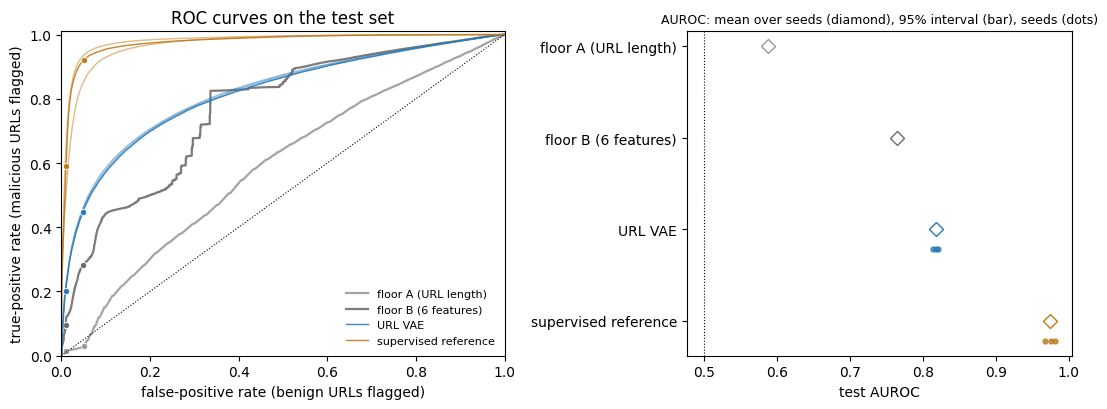

In [15]:
# ROC curves, and AUROC with its interval: the floors, the URL VAE and the supervised reference
ENTRIES = [("floor A (URL length)", *FLOOR_A, "#9a9a9a"), ("floor B (6 features)", *FLOOR_B, "#6d6d6d"),
           ("URL VAE", "url_vae", SCORE, "#2a7ab9"), ("supervised reference", "url_supervised", "prob_malicious", "#c07a1a")]
plot_detection(an, ENTRIES);

### 8.2 Where the score separates the classes

The headline score of benign and malicious test URLs, overall and inside the two largest URL schemes. A VAE that works puts the malicious curve to the right of the benign one in every panel. Curves that overlap everywhere would mean the VAE does not make anomalies stand out, which is the failure Bouman and Heskes (2025) describe. A gap overall that disappears inside the scheme panels would mean the VAE mostly learned the scheme shortcut. Read it with the strata figure in section 6.

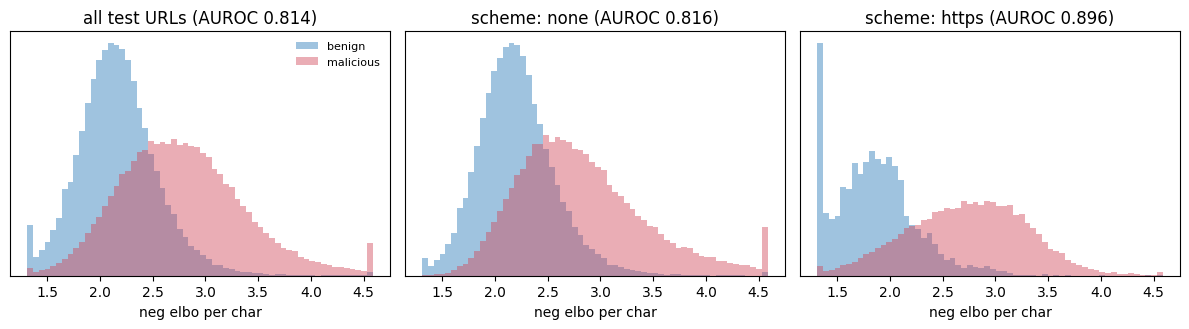

In [16]:
# The score of benign and malicious test URLs: all of them, then within the two largest schemes
plot_score_distributions(an, "url_vae", SCORE);

### 8.3 What the decoder finds surprising

The text version of a reconstruction. Each character of a URL is coloured by its negative log-likelihood under the decoder, given the posterior mean code `z`. A dark character is one the model could not predict from `z` and the characters before it. A uniform guess over the 97 symbols costs 4.6 nats, so a character darker than that is worse than not knowing. The examples are chosen by score alone, from URLs of 12 to 70 characters: the two benign URLs with the highest score (false alarms), the two nearest the benign median, the two malicious URLs with the highest score (caught), and the two with the lowest (missed). They show the extremes and not a random sample. Characters outside printable ASCII appear as `?`, as the model sees them.

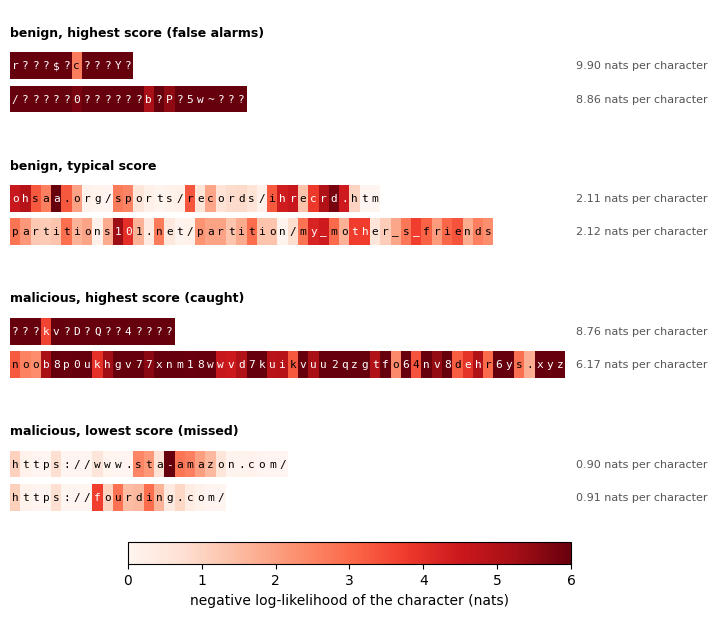

In [17]:
# Load the seed 0 model and the encoded test URLs, then colour the characters of the example URLs
device = get_device("auto")
model = load_vae(ARTIFACTS_DIR / "url_vae" / "seed0", device)
test_enc = encode_items(an.test)
score0 = an.view("url_vae", SCORE, 0).score
examples = surprise_examples(an.test, score0)
plot_surprise(examples, example_nll(model, an.test, test_enc, examples["position"], device));

### 8.4 Latent space

The posterior mean `mu` of 2,000 benign and 2,000 malicious test URLs (random), projected on its first two principal components. Coloured by class. Two components show only part of the structure, so separation that is missing here can still exist in other directions. The title counts the **active** latent dimensions (those whose posterior mean varies across URLs with a variance above 0.01). Zero active dimensions means posterior collapse: the decoder ignores `z` and the plot shows nothing about the data.

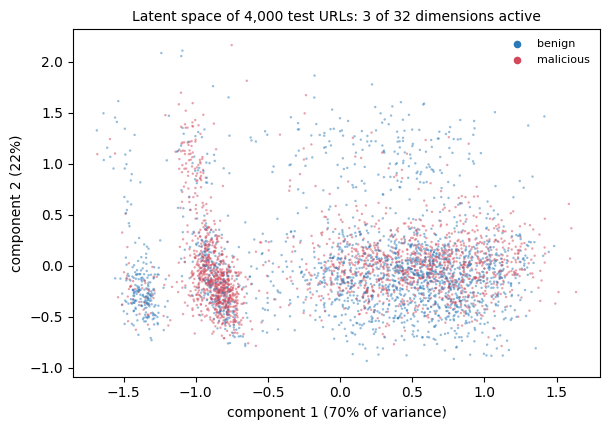

In [18]:
# Project the posterior means of a class-balanced test sample on two principal components
pos, mu = latent_sample(model, an.test, test_enc, device)
coords, explained = pca_2d(mu)
plot_latent(coords, an.y[pos], explained, active_units(mu), model.cfg.latent);

### 8.5 Samples from the prior

URLs written by the decoder from `z` drawn from the prior N(0, I). They show what the generative model has learned about the look of a benign URL. The model has no end-of-URL token, so each sample is cut at 60 characters.

In [19]:
# Twelve URLs generated from the prior (first 60 characters)
pd.DataFrame({"sample": prior_samples(model, 12, 60, device)})

,sample
0,bobentevergs.ca.hometettorbage.com/konary/gusi...
1,iec-blogream.org/doitet/diing-2001/Manchemerny...
2,reviewwork.com/clester_statemadies_for/Canada_...
3,myspatular.com/injeargielemafers/the/manzatdin...
4,halths.ongl.beskcthingur-syotth.blogspot.com/s...
5,fanningshowsle.com/awneyesrimed-wilpians-hase-...
6,www.espers.com/flight-famescheo-in/rebbake/pro...
7,basorks.geaps.com/2011611/10/ball-Apany-Schape...
8,myspaces.com/abon:Trave/19896.cgtv?t=548499021...
9,en.wikipedia.org/wiki/html/lintageo.html?id=40...
